# Global Shark Attack Data Analysis

I explored 6,300 recorded shark attack incidents using Python, pandas and Matplotlib. I focused on three questions: how fatal outcomes vary by activity, how provoked incidents differ by reported sex, and what the records show about identified shark species.

This analysis describes reported incidents, not a person's chance of being attacked. The cleaned dataset was supplied for a university exercise and is not included here because its redistribution rights have not been confirmed.

In [1]:
# Load the supplied cleaned dataset
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("data/shark-attacks-cleaned.csv", index_col=0)

print("\nThe First three rows:")
print(data.head(3))
print("\nDataset Information:")
data.info()



The First three rows:
   Year Month Country        Area        Type  Activity Sex   Age Fatal  \
0  2018   Jun     USA  California     Boating  Paddling   F  57.0     N   
1  2018   Jun     USA     Georgia  Unprovoked  Standing   F  11.0     N   
2  2018   Jun     USA      Hawaii     Invalid   Surfing   M  48.0     N   

  Injury Species  Size (min)  Size (max)  
0  Minor   White         NaN         NaN  
1  Minor     NaN         NaN         NaN  
2  Minor     NaN         NaN         NaN  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 6300 entries, 0 to 6301
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Year        6300 non-null   int64  
 1   Month       5781 non-null   object 
 2   Country     6250 non-null   object 
 3   Area        5845 non-null   object 
 4   Type        6296 non-null   object 
 5   Activity    5756 non-null   object 
 6   Sex         5731 non-null   object 
 7   Age   

In [2]:

print("\nThe Last few rows:")
print(data.tail())
print("\nSummary Statistics:")
print(data.describe())


The Last few rows:
      Year Month             Country               Area        Type  \
6297     0   NaN           AUSTRALIA  Western Australia  Unprovoked   
6298     0   NaN           AUSTRALIA  Western Australia  Unprovoked   
6299     0   NaN                 USA     North Carolina  Unprovoked   
6300     0   NaN              PANAMA                NaN  Unprovoked   
6301     0   NaN  CEYLON (SRI LANKA)   Eastern Province  Unprovoked   

          Activity Sex   Age Fatal Injury Species  Size (min)  Size (max)  
6297        Diving   M   NaN     Y  Fatal     NaN         NaN         NaN  
6298  Pearl diving   M   NaN     Y  Fatal     NaN         NaN         NaN  
6299      Swimming   M   NaN     Y  Fatal     NaN         NaN         NaN  
6300           NaN   M   NaN     Y  Fatal     NaN         NaN         NaN  
6301      Swimming   M  15.0     Y  Fatal     NaN         NaN         NaN  

Summary Statistics:


              Year          Age   Size (min)   Size (max)
count  6300.000000  3368.000000  1976.000000  1976.000000
mean   1927.272381    27.366093   255.439777   267.893219
std     281.116308    13.909223   136.289556   141.190139
min       0.000000     1.000000     2.000000     2.000000
25%    1942.000000    17.000000   150.000000   152.000000
50%    1977.000000    24.000000   213.000000   240.000000
75%    2005.000000    35.000000   350.000000   366.000000
max    2018.000000    87.000000  1006.000000  1006.000000


## Dataset overview and quality checks

The dataset contains 6,300 incidents and 13 columns, covering when and where attacks were recorded, what people were doing, incident type, injuries, fatal outcomes and shark species.

Not every record is complete. Age, species and shark size are missing in many cases, and a year of 0 means the date is unknown. These gaps matter, especially when comparing small groups or looking for patterns over time.

The analysis uses the categories and outcomes recorded in the dataset. Without information about how many people took part in each activity, it cannot measure the actual risk of a shark attack. The CSV is excluded from this repository because permission to redistribute it has not been confirmed.

## Question 1 — How does recorded fatality proportion vary by activity?

I selected the four activities appearing most often in the dataset. For each one, I divided the number of incidents marked fatal (`Y`) by the number with a known outcome (`Y` or `N`).

That gives the fatality proportion **among recorded incidents with known outcomes**. It does not tell us how likely someone is to be attacked while doing that activity.

In [3]:
# count how many times each activity appears
activity_counts = {}
for i in range(len(data)):
    activity = data['Activity'].iloc[i]
    if str(activity) == 'nan':
        continue
    if activity in activity_counts:
        activity_counts[activity] = activity_counts[activity] + 1
    else:
        activity_counts[activity] = 1

# step 2: sort and get top 4 activities
sorted_activities = sorted(activity_counts, key=activity_counts.get, reverse=True)
common_activities = sorted_activities[:4]
print('Most common activities found:', common_activities)

# step 3: count total and fatal attacks for each activity
attacks_per_activity = {}
fatal_attacks_per_activity = {}

for i in range(len(data)):
    activity = data['Activity'].iloc[i]
    fatal = data['Fatal'].iloc[i]

    if str(activity) == 'nan':
        continue

    if activity in common_activities:
        if fatal == 'Y' or fatal == 'N':
            if activity in attacks_per_activity:
                attacks_per_activity[activity] = attacks_per_activity[activity] + 1
            else:
                attacks_per_activity[activity] = 1

            if fatal == 'Y':
                if activity in fatal_attacks_per_activity:
                    fatal_attacks_per_activity[activity] = fatal_attacks_per_activity[activity] + 1
                else:
                    fatal_attacks_per_activity[activity] = 1

# calculate fatality rate for each activity
print('Fatality rates by activity:')
for activity in attacks_per_activity:
    total = attacks_per_activity[activity]
    fatal = 0
    if activity in fatal_attacks_per_activity:
        fatal = fatal_attacks_per_activity[activity]
    rate = (fatal / total) * 100
    print(str(activity) + ': ' + str(round(rate, 1)) + '%')

Most common activities found: ['Surfing', 'Swimming', 'Fishing', 'Spearfishing']
Fatality rates by activity:
Surfing: 5.3%
Swimming: 39.2%
Fishing: 11.5%
Spearfishing: 13.4%


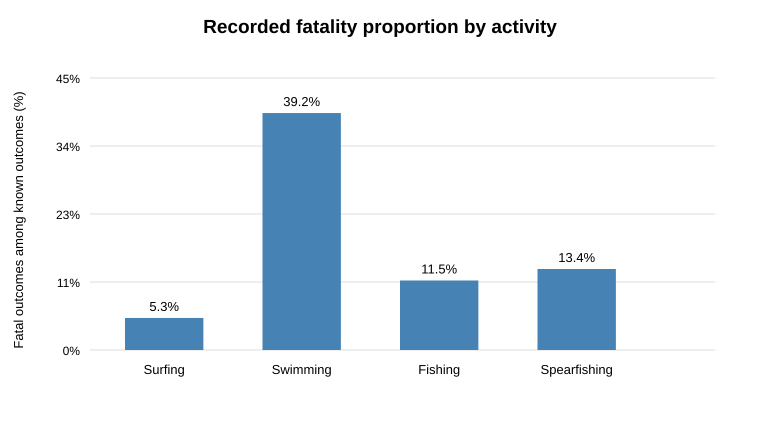

In [4]:
# Recalculate the plotted values from the counts above
activity_names = list(attacks_per_activity.keys())
fatality_rates = [
    round(100 * fatal_attacks_per_activity.get(activity, 0) / attacks_per_activity[activity], 1)
    for activity in activity_names
]

plt.figure(figsize=(10, 6))
bars = plt.bar(activity_names, fatality_rates, color='steelblue')
plt.ylabel('Fatal outcomes among recorded incidents (%)')
plt.title('Recorded fatality proportion by activity')
plt.ylim(0, max(fatality_rates) * 1.18)
plt.grid(axis='y', linestyle='--', alpha=0.4)
for bar, rate in zip(bars, fatality_rates):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{rate:.1f}%', ha='center')
plt.tight_layout()
plt.show()

### What the chart shows

Of the four activities, swimming had the highest recorded fatality proportion at **39.2%**. Surfing was the lowest at **5.3%**, followed by fishing at **11.5%** and spearfishing at **13.4%**.

The gap is notable, but it doesn't mean swimming is necessarily the most dangerous activity overall. We don't know how many people were swimming or surfing, and missing outcomes or differences in reporting could affect the comparison.

## Question 2 — How does the share of provoked incidents differ by reported sex?

I compared incidents labelled *Provoked*, *Unprovoked* or *Boating* for people recorded as male (`M`) or female (`F`). Because the number of records differs greatly between the groups, I compared percentages within each group rather than raw counts.

These labels describe how incidents were recorded. They don't establish anyone's intentions or behaviour.

In [5]:
# define valid attack types and filter data manually
valid_attack_types = ['Unprovoked', 'Provoked', 'Boating']

filtered_rows = []
for i in range(len(data)):
    attack_type = data['Type'].iloc[i]
    gender = data['Sex'].iloc[i]

    if str(attack_type) == 'nan' or str(gender) == 'nan':
        continue

    if attack_type in valid_attack_types:
        if gender == 'M' or gender == 'F':
            filtered_rows.append(i)

gender_and_type_data = data.iloc[filtered_rows].copy()

# count total attacks for each gender
total_male_attacks = 0
total_female_attacks = 0

for i in range(len(gender_and_type_data)):
    gender = gender_and_type_data['Sex'].iloc[i]
    if gender == 'M':
        total_male_attacks = total_male_attacks + 1
    if gender == 'F':
        total_female_attacks = total_female_attacks + 1

# count provoked attacks for each gender
male_provoked_count = 0
female_provoked_count = 0

for i in range(len(gender_and_type_data)):
    gender = gender_and_type_data['Sex'].iloc[i]
    attack_type = gender_and_type_data['Type'].iloc[i]

    if gender == 'M' and attack_type == 'Provoked':
        male_provoked_count = male_provoked_count + 1
    if gender == 'F' and attack_type == 'Provoked':
        female_provoked_count = female_provoked_count + 1

# calculate percentages
male_provoked_percentage = (male_provoked_count / total_male_attacks) * 100
female_provoked_percentage = (female_provoked_count / total_female_attacks) * 100

print('Total male attacks: ' + str(total_male_attacks))
print('Male provoked attacks: ' + str(male_provoked_count) + ' (' + str(round(male_provoked_percentage, 1)) + '%)')
print()
print('Total female attacks: ' + str(total_female_attacks))
print('Female provoked attacks: ' + str(female_provoked_count) + ' (' + str(round(female_provoked_percentage, 1)) + '%)')
print()

# breakdown by attack type and gender
all_types = []
for i in range(len(gender_and_type_data)):
    attack_type = gender_and_type_data['Type'].iloc[i]
    if attack_type not in all_types:
        all_types.append(attack_type)

breakdown = {}
for attack_type in all_types:
    male_count = 0
    female_count = 0
    for i in range(len(gender_and_type_data)):
        if gender_and_type_data['Type'].iloc[i] == attack_type:
            if gender_and_type_data['Sex'].iloc[i] == 'M':
                male_count = male_count + 1
            if gender_and_type_data['Sex'].iloc[i] == 'F':
                female_count = female_count + 1
    breakdown[attack_type] = {'M': male_count, 'F': female_count}

print('Full breakdown by attack type:')
print('Type'.ljust(15) + 'M'.ljust(10) + 'F')
print('-' * 30)
for attack_type in breakdown:
    m = breakdown[attack_type]['M']
    f = breakdown[attack_type]['F']
    print(str(attack_type).ljust(15) + str(m).ljust(10) + str(f))

Total male attacks: 4514
Male provoked attacks: 494 (10.9%)

Total female attacks: 566
Female provoked attacks: 22 (3.9%)

Full breakdown by attack type:
Type           M         F
------------------------------
Boating        124       9
Unprovoked     3896      535
Provoked       494       22


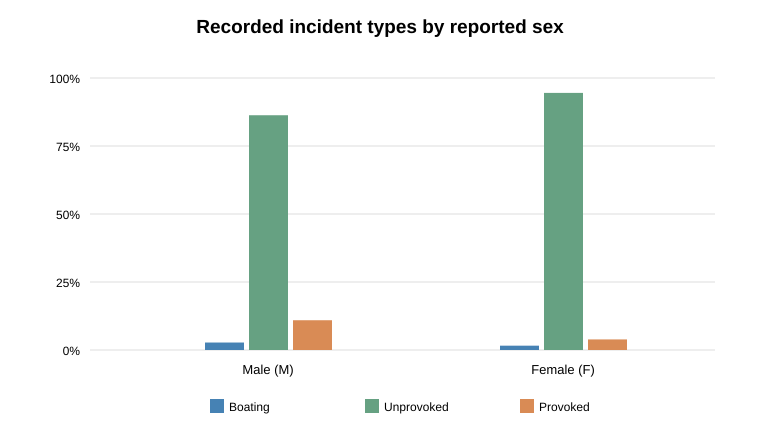

In [6]:
# Percentages within each reported-sex group, using the breakdown above
all_types = ['Boating', 'Unprovoked', 'Provoked']
male_percentages = {t: 100 * breakdown[t]['M'] / total_male_attacks for t in all_types}
female_percentages = {t: 100 * breakdown[t]['F'] / total_female_attacks for t in all_types}

import numpy as np
x = np.arange(2)
width = 0.24
fig, ax = plt.subplots(figsize=(10, 6))
for j, attack_type in enumerate(all_types):
    ax.bar(x + (j - 1) * width,
           [male_percentages[attack_type], female_percentages[attack_type]],
           width, label=attack_type)
ax.set_xticks(x)
ax.set_xticklabels(['Male (M)', 'Female (F)'])
ax.set_ylabel('Share of included incidents (%)')
ax.set_title('Recorded incident types by reported sex')
ax.legend(title='Incident type')
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### What the chart shows

Provoked incidents made up **494 of 4,514** male-labelled cases (**10.9%**), compared with **22 of 566** female-labelled cases (**3.9%**). So, within the records included here, the proportion was higher for the male group.

That doesn't prove men are more likely to provoke sharks in general. Activities, exposure and reporting may differ between groups. Records with missing or other sex labels, or incident types outside the three selected, were not included.

## Question 3 — How do identified species compare in attack count and fatality proportion?

I compared two measures for species with at least 20 relevant records: **how many attacks were attributed to each species**, and **what proportion of incidents with known outcomes were fatal**.

These measures can tell different stories. Species identification is missing or uncertain in many records, so the chart is a comparison of the identified cases—not a definitive ranking of which sharks are most dangerous.

In [7]:
# count how many attacks each species has
species_counts = {}
for i in range(len(data)):
    species = data['Species'].iloc[i]
    fatal = data['Fatal'].iloc[i]

    if str(species) == 'nan' or str(fatal) == 'nan':
        continue

    if species in species_counts:
        species_counts[species] = species_counts[species] + 1
    else:
        species_counts[species] = 1

# keep only species with at least 20 attacks
common_species = []
for species in species_counts:
    if species_counts[species] >= 20:
        common_species.append(species)

# count total and fatal attacks for each common species
attacks_per_species = {}
fatal_per_species = {}

for i in range(len(data)):
    species = data['Species'].iloc[i]
    fatal = data['Fatal'].iloc[i]

    if str(species) == 'nan' or str(fatal) == 'nan':
        continue

    if species in common_species:
        if fatal == 'Y' or fatal == 'N':
            if species in attacks_per_species:
                attacks_per_species[species] = attacks_per_species[species] + 1
            else:
                attacks_per_species[species] = 1

            if fatal == 'Y':
                if species in fatal_per_species:
                    fatal_per_species[species] = fatal_per_species[species] + 1
                else:
                    fatal_per_species[species] = 1

# calculate fatality rate for each species
fatal_rates = {}
for species in attacks_per_species:
    total = attacks_per_species[species]
    fatal = 0
    if species in fatal_per_species:
        fatal = fatal_per_species[species]
    fatal_rates[species] = (fatal / total) * 100

# sort species by attack count and print summary
sorted_species = sorted(attacks_per_species, key=attacks_per_species.get, reverse=True)

print('Species comparison:')
print('Species'.ljust(25) + 'Attack Count'.ljust(20) + 'Fatality Rate')
print('-' * 55)
for species in sorted_species:
    total = attacks_per_species[species]
    rate = round(fatal_rates[species], 1)
    print(str(species).ljust(25) + str(total).ljust(20) + str(rate) + '%')

Species comparison:
Species                  Attack Count        Fatality Rate
White                    173                 27.7%
Tiger                     80                 35.0%
Bull                      56                 33.9%
Wobbegong                 21                  0.0%
Zambesi                   20                 40.0%


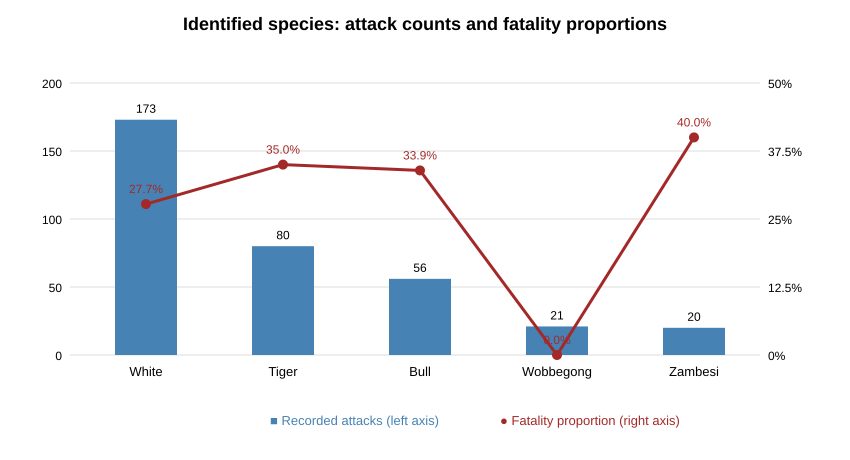

In [8]:
# Build the chart directly from the computed dictionaries
species_stats = pd.DataFrame([
    {'Species': species,
     'total_attacks': attacks_per_species[species],
     'fatality_rate': fatal_rates[species]}
    for species in sorted_species
])

fig, ax = plt.subplots(figsize=(11, 6))
x = range(len(species_stats))
ax.bar(x, species_stats['total_attacks'], color='steelblue', label='Recorded attacks')
ax.set_ylabel('Recorded attacks (count)')
ax.set_xticks(list(x))
ax.set_xticklabels(species_stats['Species'], rotation=30, ha='right')
ax.set_title('Identified species: attack counts and fatality proportions')
ax2 = ax.twinx()
ax2.plot(list(x), species_stats['fatality_rate'], color='darkred', marker='o',
         linewidth=2, label='Fatality proportion')
ax2.set_ylabel('Fatal outcomes among known outcomes (%)')
ax2.set_ylim(0, max(45, species_stats['fatality_rate'].max() * 1.2))
for i, rate in enumerate(species_stats['fatality_rate']):
    ax2.annotate(f'{rate:.1f}%', (i, rate), xytext=(0, 7),
                 textcoords='offset points', ha='center', color='darkred')
fig.tight_layout()
plt.show()

### What the chart shows

White sharks had the most recorded attacks among the selected species (**173**), followed by tiger sharks (**80**) and bull sharks (**56**). Their recorded fatality proportions were **27.7%**, **35.0%** and **33.9%**, respectively.

Zambesi sharks had the highest fatality proportion in this comparison (**40.0%**), but that figure comes from just **20** incidents. Wobbegong sharks had **21** recorded incidents and **0.0%** fatal outcomes in the included records.

There's no single answer to “which species is most dangerous?” White sharks lead in recorded attack count, while Zambesi sharks lead in fatality proportion in this small selection. Missing species identifications and small samples limit how far we can take either result.

### Overall takeaway

The clearest lesson is that **counts and percentages answer different questions**. Swimming had the highest fatality proportion among the four activities compared, provoked incidents made up a higher share of male-labelled records, and the leading species changed depending on the measure used. These findings describe the dataset; they don't establish causes or an individual's real-world risk.